In [1]:
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, Input
from tensorflow.keras.optimizers import Adam

print(f"TensorFlow Version: {tf.__version__}")

TensorFlow Version: 2.21.0


In [2]:
base_dir = os.getcwd()
dataset_dir = os.path.join(base_dir, 'dataset')
with_mask_dir = os.path.join(dataset_dir, 'with_mask')
without_mask_dir = os.path.join(dataset_dir, 'without_mask')

num_with_mask = len(os.listdir(with_mask_dir)) if os.path.exists(with_mask_dir) else 0
num_without_mask = len(os.listdir(without_mask_dir)) if os.path.exists(without_mask_dir) else 0

print(f"Number of 'with_mask' images: {num_with_mask}")
print(f"Number of 'without_mask' images: {num_without_mask}")

Number of 'with_mask' images: 1005
Number of 'without_mask' images: 1004


In [3]:
IMG_HEIGHT, IMG_WIDTH = 128, 128
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    rescale=1.0 / 255.0,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest',
    validation_split=0.2
)

print("Loading Training Dataset:")
train_generator = train_datagen.flow_from_directory(
    dataset_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    shuffle=True
)

print("\nLoading Validation Dataset:")
val_generator = train_datagen.flow_from_directory(
    dataset_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)

print(f"\nClass Indices Mapping: {train_generator.class_indices}")

Loading Training Dataset:
Found 1608 images belonging to 2 classes.

Loading Validation Dataset:
Found 401 images belonging to 2 classes.

Class Indices Mapping: {'with_mask': 0, 'without_mask': 1}


In [4]:
model = Sequential([
    Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3)),
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    
    Dropout(0.5),
    Flatten(),
    
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(2, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     7,372,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,392,578 (28.20 MB)

 Trainable params: 7,392,578 (28.20 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

EPOCHS = 15
history = model.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=val_generator
)

Epoch 1/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 37s 659ms/step - accuracy: 0.7270 - loss: 0.6160 - val_accuracy: 0.7481 - val_loss: 0.8231
Epoch 2/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 37s 718ms/step - accuracy: 0.9067 - loss: 0.2532 - val_accuracy: 0.8204 - val_loss: 0.6473
Epoch 3/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 32s 623ms/step - accuracy: 0.9359 - loss: 0.1839 - val_accuracy: 0.8579 - val_loss: 0.3323
Epoch 4/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 32s 631ms/step - accuracy: 0.9335 - loss: 0.1752 - val_accuracy: 0.8853 - val_loss: 0.2850
Epoch 5/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 32s 621ms/step - accuracy: 0.9546 - loss: 0.1355 - val_accuracy: 0.7930 - val_loss: 0.5895
Epoch 6/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 35s 690ms/step - accuracy: 0.9509 - loss: 0.1376 - val_accuracy: 0.8828 - val_loss: 0.3012
Epoch 7/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 38s 732ms/step - accuracy: 0.9596 - loss: 0.1074 - val_accuracy: 0.9501 - val_loss: 0.1783
Epoch 8/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 36s 696ms/step - accuracy: 0.9496 - loss: 0.1419 - val_accu

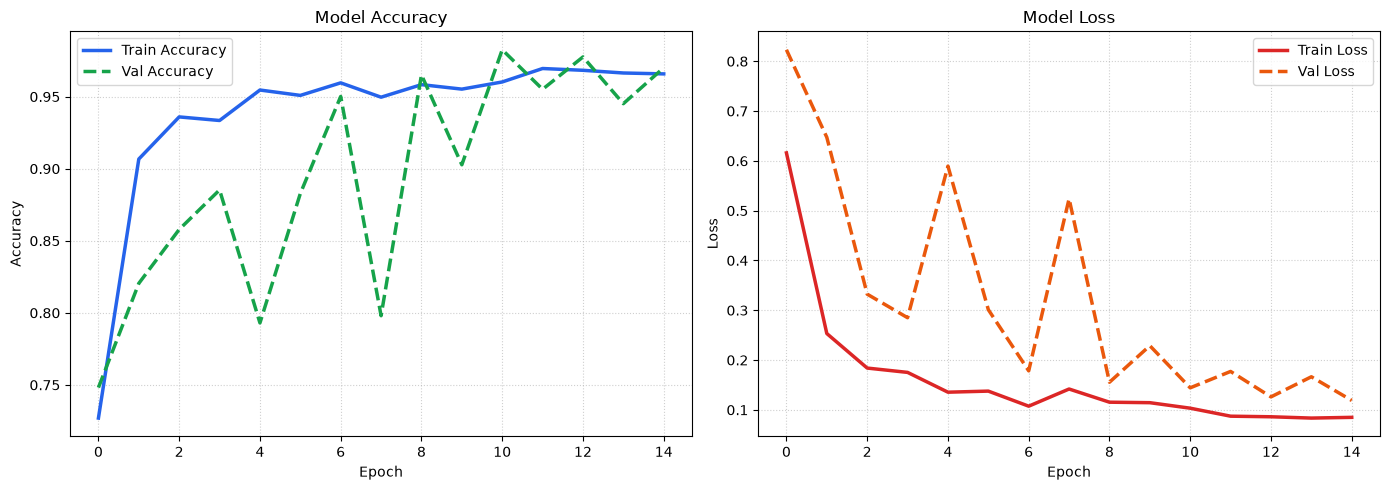

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy Plot
axes[0].plot(history.history['accuracy'], label='Train Accuracy', color='#2563eb', linewidth=2.5)
axes[0].plot(history.history['val_accuracy'], label='Val Accuracy', color='#16a34a', linewidth=2.5, linestyle='--')
axes[0].set_title('Model Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.6)

# Loss Plot
axes[1].plot(history.history['loss'], label='Train Loss', color='#dc2626', linewidth=2.5)
axes[1].plot(history.history['val_loss'], label='Val Loss', color='#ea580c', linewidth=2.5, linestyle='--')
axes[1].set_title('Model Loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig('accuracy_loss_plot.png', dpi=300)
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 271ms/step


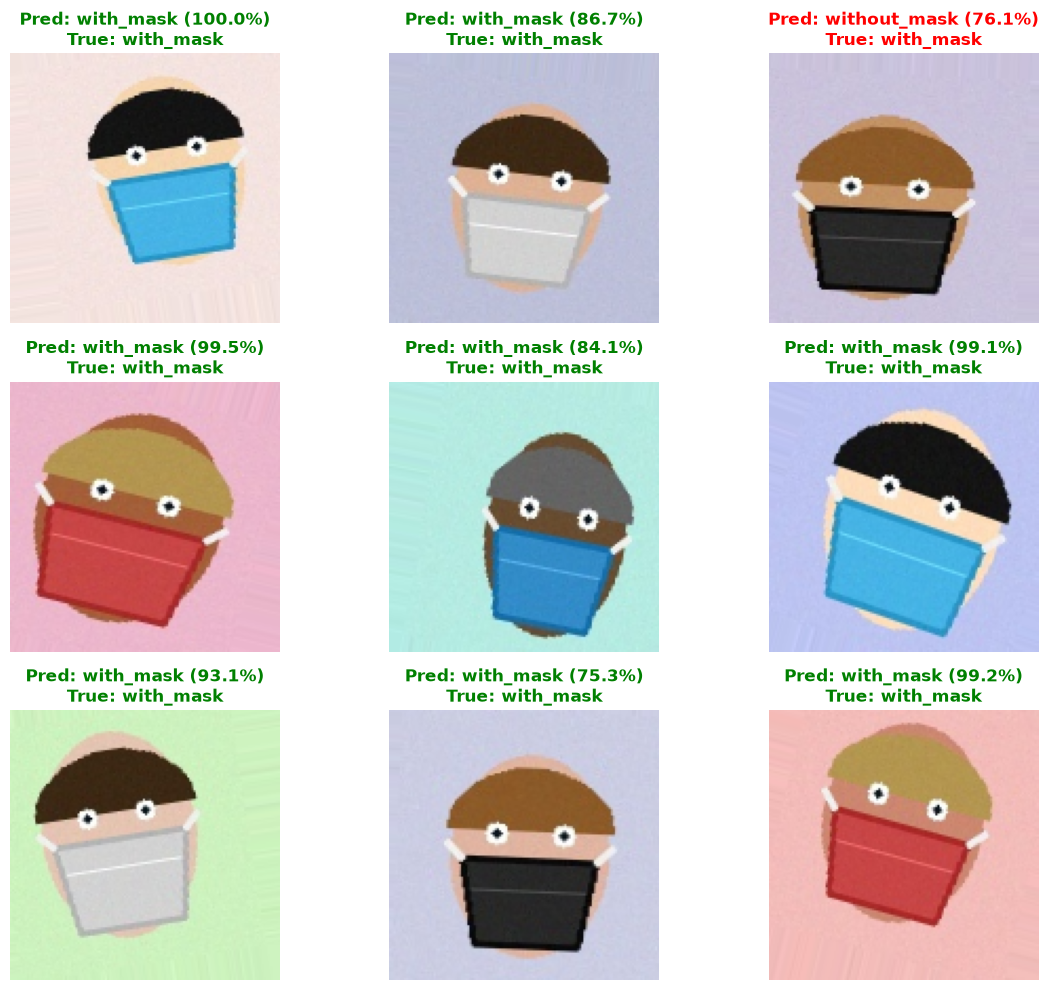

In [7]:
inv_class_map = {0: 'with_mask', 1: 'without_mask'}
val_images, val_labels = next(val_generator)
predictions = model.predict(val_images)

plt.figure(figsize=(12, 10))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    img = val_images[i]
    true_idx = np.argmax(val_labels[i])
    pred_idx = np.argmax(predictions[i])
    confidence = predictions[i][pred_idx] * 100
    
    true_label = inv_class_map[true_idx]
    pred_label = inv_class_map[pred_idx]
    color = 'green' if true_idx == pred_idx else 'red'
    
    plt.imshow(img)
    plt.title(f"Pred: {pred_label} ({confidence:.1f}%)\nTrue: {true_label}", color=color, fontweight='bold')
    plt.axis('off')

plt.tight_layout()
plt.savefig('sample_predictions.png', dpi=300)
plt.show()

In [8]:
model.save('face_mask_model.keras')
print("Model saved successfully as face_mask_model.keras!")

Model saved successfully as face_mask_model.keras!
